<a href="https://colab.research.google.com/github/fauzia-annisa/ModShield-Cascaded-LLM-Moderation-Agent/blob/main/ModShield_Cascaded_LLM_Moderation_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 0: Colab setup

In [1]:
!pip -q install -U datasets transformers accelerate scikit-learn
import torch; print(torch.cuda.is_available())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
True


Step 1: Load real data

In [2]:
import pandas as pd, numpy as np, time
from datasets import load_dataset

raw = load_dataset("google/civil_comments")
tr = raw["train"].shuffle(seed=42).select(range(60000)).to_pandas()
va = raw["validation"].shuffle(seed=42).select(range(5000)).to_pandas()
te = raw["test"].shuffle(seed=42).select(range(10000)).to_pandas()
for d in (tr, va, te):
    d["y"] = (d["toxicity"] >= 0.5).astype(int)

print(tr.y.mean(), tr.columns.tolist())
ID = [c for c in ["male","female","homosexual_gay_or_lesbian","christian",
      "jewish","muslim","black","white","psychiatric_or_mental_illness"] if c in te.columns]
print(ID)

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

0.07825 ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'y']
[]


Step 2: Metrics helpers

In [3]:
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

def thr_from_val(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f = 2*pr*rc/(pr+rc+1e-9)
    return th[f[:-1].argmax()]

def f1_at(y, p, t):
    pred = p >= t
    tp = (pred & (y==1)).sum(); fp = (pred & (y==0)).sum(); fn = (~pred & (y==1)).sum()
    return 2*tp/(2*tp+fp+fn+1e-9)

def report(name, col):
    t = thr_from_val(va.y, va[col])
    print(f"{name}: PR-AUC={average_precision_score(te.y, te[col]):.3f} "
          f"ROC-AUC={roc_auc_score(te.y, te[col]):.3f} F1={f1_at(te.y, te[col], t):.3f} thr={t:.2f}")
    return t

Step 3: Baseline (Stage 1)



In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(ngram_range=(1,2), min_df=3, max_features=300000, sublinear_tf=True)
Xtr = vec.fit_transform(tr.text)
lr = LogisticRegression(C=4, max_iter=300, class_weight="balanced").fit(Xtr, tr.y)

va["p_lr"] = lr.predict_proba(vec.transform(va.text))[:,1]
t0 = time.time()
te["p_lr"] = lr.predict_proba(vec.transform(te.text))[:,1]
lat_lr = (time.time()-t0)/len(te)*1000
thr_lr = report("TFIDF+LR", "p_lr"); print("ms/comment", lat_lr)

TFIDF+LR: PR-AUC=0.584 ROC-AUC=0.898 F1=0.543 thr=0.53
ms/comment 0.15817732810974122


Step 4: Fine-tune DistilBERT (Stage 2, PyTorch)

In [5]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from datasets import Dataset
from scipy.special import softmax

mn = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(mn)

def enc(df):
    ds = Dataset.from_dict({"text": df.text.tolist(), "label": df.y.tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=128), batched=True)

dtr, dva, dte = enc(tr.sample(30000, random_state=1)), enc(va), enc(te)
model = AutoModelForSequenceClassification.from_pretrained(mn, num_labels=2)
args = TrainingArguments("bert_out", per_device_train_batch_size=32,
        per_device_eval_batch_size=64, num_train_epochs=2, learning_rate=3e-5,
        fp16=True, save_strategy="no", report_to="none")
trainer = Trainer(model=model, args=args, train_dataset=dtr,
                  data_collator=DataCollatorWithPadding(tok))
trainer.train()

def predict(ds): return softmax(trainer.predict(ds).predictions, axis=1)[:,1]
va["p_bert"] = predict(dva)
t0 = time.time(); te["p_bert"] = predict(dte)
lat_bert = (time.time()-t0)/len(te)*1000
thr_bert = report("DistilBERT", "p_bert"); print("ms/comment", lat_bert)
trainer.save_model("model"); tok.save_pretrained("model")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

... (5 outputs left out)

Step,Training Loss
500,0.193690
1000,0.145622
1500,0.104101


DistilBERT: PR-AUC=0.700 ROC-AUC=0.939 F1=0.652 thr=0.39
ms/comment 0.9629329681396485


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('model/tokenizer_config.json', 'model/tokenizer.json')

Step 5: The LLM agent (Stage 3)

In [6]:
from transformers import AutoModelForCausalLM
from sklearn.neighbors import NearestNeighbors

lm_name = "Qwen/Qwen2.5-1.5B-Instruct"
ltok = AutoTokenizer.from_pretrained(lm_name, padding_side="left")
llm = AutoModelForCausalLM.from_pretrained(lm_name, torch_dtype=torch.float16,
                                           device_map="cuda").eval()
nn = NearestNeighbors(n_neighbors=4, metric="cosine").fit(Xtr)

POLICY = """You are a content-moderation agent for a Q&A platform.
Label A (TOXIC): harassment, insults or personal attacks, threats, hate toward a group or identity, obscene or sexual abuse.
Label B (OK): criticism, disagreement, profanity not aimed at anyone, discussing or quoting offensive content, neutral mention of an identity group.
Answer with a single letter."""

def build(text, ex):
    shots = "\n".join(f"Comment: {t[:200]!r}\nLabel: {'A' if y else 'B'}" for t, y in ex)
    msgs = [{"role":"system","content":POLICY},
            {"role":"user","content":f"Similar past cases:\n{shots}\n\nLabel this comment.\nComment: {text[:600]!r}\nAnswer A or B."}]
    return ltok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

A = ltok.encode("A", add_special_tokens=False)[0]
B = ltok.encode("B", add_special_tokens=False)[0]

@torch.no_grad()
def llm_score(texts, bs=8):
    out = []
    for i in range(0, len(texts), bs):
        chunk = texts[i:i+bs]
        _, idx = nn.kneighbors(vec.transform(chunk))
        prompts = [build(t, [(tr.text.iloc[j], tr.y.iloc[j]) for j in ix])
                   for t, ix in zip(chunk, idx)]
        b = ltok(prompts, return_tensors="pt", padding=True).to("cuda")
        lg = llm(**b).logits[:, -1, :]
        out += torch.softmax(lg[:, [A, B]].float(), -1)[:, 0].cpu().tolist()
    return out

# Only score the uncertain band (this is the cost saving)
for d in (va, te):
    m = (d.p_bert > 0.1) & (d.p_bert < 0.9)
    print(m.sum(), "rows in band")
    t0 = time.time()
    d.loc[m, "p_llm"] = llm_score(d.loc[m, "text"].tolist())
    if d is te: lat_llm = (time.time()-t0)/m.sum()*1000
print("LLM ms/comment", lat_llm)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

364 rows in band
802 rows in band
LLM ms/comment 88.85622381272161


Step 6: Cascade and the cost vs. accuracy table

 w_bert      band  pct_to_llm  PR_AUC  F1_val  F1_test   ms
   1.00 BERT only         0.0   0.700   0.674    0.652 0.96
   0.75   0.4-0.6         1.4   0.700   0.674    0.652 2.22
   0.75 0.25-0.75         3.7   0.700   0.674    0.649 4.28
   0.75   0.1-0.9         8.0   0.700   0.674    0.649 8.09
   0.50   0.4-0.6         1.4   0.699   0.674    0.652 2.22
   0.50 0.25-0.75         3.7   0.698   0.671    0.648 4.28
   0.50   0.1-0.9         8.0   0.698   0.669    0.646 8.09
   0.25   0.4-0.6         1.4   0.693   0.674    0.652 2.22
   0.25 0.25-0.75         3.7   0.689   0.667    0.642 4.28
   0.25   0.1-0.9         8.0   0.694   0.663    0.647 8.09
   0.00   0.4-0.6         1.4   0.567   0.674    0.652 2.22
   0.00 0.25-0.75         3.7   0.483   0.667    0.640 4.28
   0.00   0.1-0.9         8.0   0.428   0.639    0.604 8.09


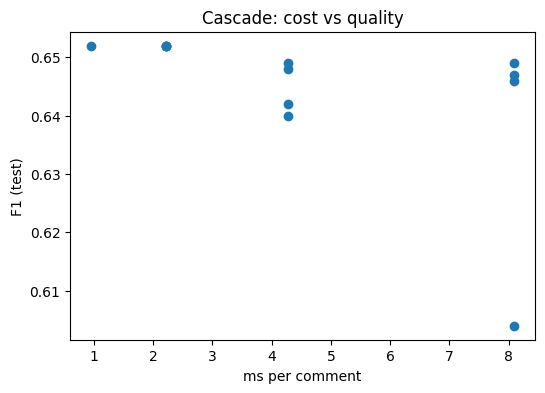

In [11]:
import matplotlib.pyplot as plt

def cascade(df, lo, hi, w=0.5):
    s = df.p_bert.astype("float64").copy()
    m = (df.p_bert > lo) & (df.p_bert < hi) & df.p_llm.notna()
    s[m] = w*df.p_bert[m].astype("float64") + (1-w)*df.p_llm[m]
    return s, m.mean()

bt = thr_from_val(va.y, va.p_bert)
rows = [dict(w_bert=1.0, band="BERT only", pct_to_llm=0.0,
             PR_AUC=round(average_precision_score(te.y, te.p_bert),3),
             F1_val=round(f1_at(va.y, va.p_bert, bt),3),
             F1_test=round(f1_at(te.y, te.p_bert, bt),3),
             ms=round(lat_bert,2))]
for w in [0.75, 0.5, 0.25, 0.0]:
    for lo, hi in [(0.4,0.6),(0.25,0.75),(0.1,0.9)]:
        sv,_ = cascade(va, lo, hi, w); st, frac = cascade(te, lo, hi, w)
        t = thr_from_val(va.y, sv)
        rows.append(dict(w_bert=w, band=f"{lo}-{hi}", pct_to_llm=round(frac*100,1),
            PR_AUC=round(average_precision_score(te.y, st),3),
            F1_val=round(f1_at(va.y, sv, t),3), F1_test=round(f1_at(te.y, st, t),3),
            ms=round(lat_bert + frac*lat_llm,2)))
res = pd.DataFrame(rows); print(res.to_string(index=False))

plt.figure(figsize=(6,4))
plt.scatter(res.ms, res.F1_test)
plt.xlabel("ms per comment"); plt.ylabel("F1 (test)"); plt.title("Cascade: cost vs quality")
plt.savefig("cascade_tradeoff.png", dpi=150, bbox_inches="tight"); plt.show()

Step 7: Bias audit

In [12]:
full = raw["test"].to_pandas()
full["y"] = (full["toxicity"] >= 0.5).astype(int)
TERMS = {
 "muslim": r"\bmuslims?\b|\bislam",
 "jewish": r"\bjew(?:s|ish)?\b",
 "gay_lgbt": r"\bgay\b|\blesbian|\bhomosexual|\blgbt",
 "black": r"\bblack (?:people|man|men|woman|women|community)|\bafrican[- ]american",
 "white": r"\bwhite (?:people|man|men|woman|women)",
 "christian": r"\bchristian",
 "women": r"\bwomen\b|\bwoman\b|\bfemale",
 "mental_illness": r"mental(?:ly)? ill|\bschizophren|\bbipolar",
}
rows = []
for g, pat in TERMS.items():
    sub = full[full.text.str.contains(pat, case=False, regex=True) & (full.y == 0)]
    if len(sub) < 30: continue
    pb = predict(enc(sub)); pl = lr.predict_proba(vec.transform(sub.text))[:,1]
    rows.append(dict(group=g, n_nontoxic=len(sub),
        FPR_lr=round((pl > thr_lr).mean(),3), FPR_bert=round((pb > thr_bert).mean(),3)))
print("overall FPR bert (test sample):", round((te.loc[te.y==0,"p_bert"]>thr_bert).mean(),3))
print(pd.DataFrame(rows))

Map:   0%|          | 0/987 [00:00<?, ? examples/s]

Map:   0%|          | 0/338 [00:00<?, ? examples/s]

Map:   0%|          | 0/396 [00:00<?, ? examples/s]

Map:   0%|          | 0/175 [00:00<?, ? examples/s]

Map:   0%|          | 0/164 [00:00<?, ? examples/s]

Map:   0%|          | 0/769 [00:00<?, ? examples/s]

Map:   0%|          | 0/2198 [00:00<?, ? examples/s]

Map:   0%|          | 0/143 [00:00<?, ? examples/s]

overall FPR bert (test sample): 0.03
            group  n_nontoxic  FPR_lr  FPR_bert
0          muslim         987   0.169     0.070
1          jewish         338   0.118     0.077
2        gay_lgbt         396   0.144     0.081
3           black         175   0.229     0.269
4           white         164   0.323     0.232
5       christian         769   0.078     0.040
6           women        2198   0.084     0.050
7  mental_illness         143   0.140     0.056


Step 8: Failure analysis

In [13]:
te["pred"] = (te.p_bert >= thr_bert).astype(int)
print("FALSE POSITIVES"); print(te[(te.pred==1)&(te.y==0)].sort_values("p_bert",ascending=False).text.head(15).to_string())
print("FALSE NEGATIVES"); print(te[(te.pred==0)&(te.y==1)].sort_values("p_bert").text.head(15).to_string())

FALSE POSITIVES
8570                                    I'm a silly dude.
2967    Goo gang. Jr.was not a private citizen. Hey fo...
6274    I have no idea what kind of legal punishment t...
9686    '“We’ve got to do a lot of education” of Trump...
9559    yuknon: Trudeau's convenient and confusing app...
7411                                   Cherry is a troll.
5469    This is the guy, and those like him, giving la...
8675    China lets North Korea run wild as a front to ...
6330    Wow. So this is how the master deal-maker does...
5202    Genie is just a passing fad......no one cares....
6031    while store shelves run empty and prices of $2...
1273    Bernstein is a has-been Loser trying desperate...
4854    To think the people of South Carolina elected ...
5205    Heard my wife and a female friend talking the ...
684     Ha ha ha ha ha ha, oh my god funny.  How many ...
FALSE NEGATIVES
2549    no, no, no, that wasn't the deal. at least 100...
2897    that is what politicians do, the

Step 9: Monitoring (drift)

In [14]:
for ft in [0.2, 0.4, 0.6]:
    n_t = int((te.y==1).sum()); n_nt = int(n_t*(1-ft)/ft)
    s = pd.concat([te[te.y==1], te[te.y==0].sample(n_nt, random_state=0)])
    print(f"{int(ft*100)}% toxic -> PSI", round(psi(va.p_bert.values, s.p_bert.values),3))

20% toxic -> PSI 0.069
40% toxic -> PSI 0.345
60% toxic -> PSI 0.786
